# Brain Connectivity and Graph Neural Networks for Autism Classification

This notebook explores resting-state fMRI connectivity in the ABIDE dataset and uses it for autism spectrum disorder (ASD) classification. The analysis follows two complementary routes: a conventional SVM built from vectorised functional connections, and a Graph Attention Network (GAT) that represents each subject's connectome explicitly as a graph.

The workflow moves from regional fMRI time series to functional connectivity, examines group-level connectivity patterns, builds a classical machine-learning baseline, and then reformulates the same data as brain graphs for graph-level classification.

> A GPU runtime is recommended for the GAT training stage.

## Setup

The analysis uses `nilearn` for neuroimaging and connectivity estimation, `scikit-learn` for the SVM baseline, and PyTorch Geometric for graph construction and the GAT model.

In [1]:
# Install necessary packages
!pip install nilearn
!pip install torch_geometric

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 6.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.5/11.5 MB 84.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 119.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.1/73.1 kB 8.6 MB/s eta 0:00:00
  Attempting uninstall: requests
    Found existing installation: requests 2.32.4
    Uninstalling requests-2.32.4:
      Successfully uninstalled requests-2.32.4
  Attempting uninstall: pandas
    Found existing installation: pandas 2.2.3
    Uninstalling pandas-2.2.3:
      Successfully uninstalled pandas-2.2.3
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.0.6 which is incompatible.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.
das

In [2]:
# Import packages
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from nilearn import datasets, connectome, plotting
from nilearn.maskers import NiftiLabelsMasker
from nilearn.image import index_img
from nilearn.connectome import ConnectivityMeasure
from nilearn.plotting import plot_connectome, plot_matrix, find_parcellation_cut_coords

from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    roc_auc_score, balanced_accuracy_score, f1_score
)
from sklearn.pipeline import Pipeline

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.data import Data, DataLoader, Dataset
from torch_geometric.nn import GATConv, global_mean_pool
from torch_geometric.utils import to_dense_adj

print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

PyTorch version: 2.11.0+cu130
CUDA available: True
Using device: cuda


## ABIDE resting-state fMRI data

Autism spectrum disorder (ASD) is associated with differences in social communication and with restricted or repetitive patterns of behaviour and interests. Here, we work with the **Autism Brain Imaging Data Exchange (ABIDE)**, a multi-site collection of functional and structural neuroimaging data assembled to support research on the neural basis of autism.

The notebook uses a preprocessed ABIDE derivative made available through `nilearn`, with regional resting-state fMRI signals extracted using the **AAL atlas**. Each subject is therefore represented by a time series over 116 anatomical brain regions.

For this analysis, 500 quality-checked subjects are requested from the ABIDE Preprocessed Connectomes Project.

In [3]:
# Download the quality-checked ABIDE subset
abide_dataset = datasets.fetch_abide_pcp(
    n_subjects=500,
    derivatives=['rois_aal'],
    quality_checked=True
)

[fetch_abide_pcp] Added README.md to /root/nilearn_data

[fetch_abide_pcp] Dataset created in /root/nilearn_data/ABIDE_pcp

[fetch_abide_pcp] Downloading data from https://s3.amazonaws.com/fcp-indi/data/Projects/ABIDE_Initiative/Phenotypic_V1_0b_preprocessed1.csv ...

[fetch_abide_pcp]  ...done. (2 seconds, 0 min)

[fetch_abide_pcp] Downloading data from https://s3.amazonaws.com/fcp-indi/data/Projects/ABIDE_Initiative/Outputs/cpac/nofilt_noglobal/rois_aal/Pitt_0050003_rois_aal.1D ...

...

[fetch_abide_pcp]  ...done. (2 seconds, 0 min)

[fetch_abide_pcp] Downloading data from https://s3.amazonaws.com/fcp-indi/data/Projects/ABIDE_Initiative/Outputs/cpac/nofilt_noglobal/rois_aal/NYU_0050960_rois_aal.1D ...

[fetch_abide_pcp]  ...done. (2 seconds, 0 min)

[fetch_abide_pcp] Downloading data from https://s3.amazonaws.com/fcp-indi/data/Projects/ABIDE_Initiative/Outputs/cpac/nofilt_noglobal/rois_aal/NYU_0050961_rois_aal.1D ...

[fetch_abide_pcp]  ...done. (2 seconds, 0 min)

The ABIDE download also provides phenotypic information such as age, sex, acquisition site, and diagnostic group. In the original `DX_GROUP` field, ASD and control participants are encoded categorically; the labels are converted below into the binary representation used throughout the notebook.

We use the term **control** rather than *healthy*. A control participant is defined here by the absence of an ASD diagnosis, not by the absence of every other medical or psychological condition.

## Inspecting the cohort

Before modelling connectivity, we inspect the structure of the downloaded dataset, the dimensionality of the regional fMRI time series, and the main phenotypic variables. The diagnosis distribution is also examined together with sex, since both are later used when constructing the train, validation, and test partitions.

Keys: ['description', 'phenotypic', 'rois_aal']

Number of subjects downloaded: 500

Shape of first subject's time-series: (196, 116)
  -> 196 time points, 116 brain regions (AAL atlas)

Phenotypic columns: ['i', 'Unnamed: 0', 'SUB_ID', 'X', 'subject', 'SITE_ID', 'FILE_ID', 'DX_GROUP', 'DSM_IV_TR', 'AGE_AT_SCAN', 'SEX', 'HANDEDNESS_CATEGORY', 'HANDEDNESS_SCORES', 'FIQ', 'VIQ', 'PIQ', 'FIQ_TEST_TYPE', 'VIQ_TEST_TYPE', 'PIQ_TEST_TYPE', 'ADI_R_SOCIAL_TOTAL_A', 'ADI_R_VERBAL_TOTAL_BV', 'ADI_RRB_TOTAL_C', 'ADI_R_ONSET_TOTAL_D', 'ADI_R_RSRCH_RELIABLE', 'ADOS_MODULE', 'ADOS_TOTAL', 'ADOS_COMM', 'ADOS_SOCIAL', 'ADOS_STEREO_BEHAV', 'ADOS_RSRCH_RELIABLE', 'ADOS_GOTHAM_SOCAFFECT', 'ADOS_GOTHAM_RRB', 'ADOS_GOTHAM_TOTAL', 'ADOS_GOTHAM_SEVERITY', 'SRS_VERSION', 'SRS_RAW_TOTAL', 'SRS_AWARENESS', 'SRS_COGNITION', 'SRS_COMMUNICATION', 'SRS_MOTIVATION', 'SRS_MANNERISMS', 'SCQ_TOTAL', 'AQ_TOTAL', 'COMORBIDITY', 'CURRENT_MED_STATUS', 'MEDICATION_NAME', 'OFF_STIMULANTS_AT_SCAN', 'VINELAND_RECEPTIVE_V_SCALE

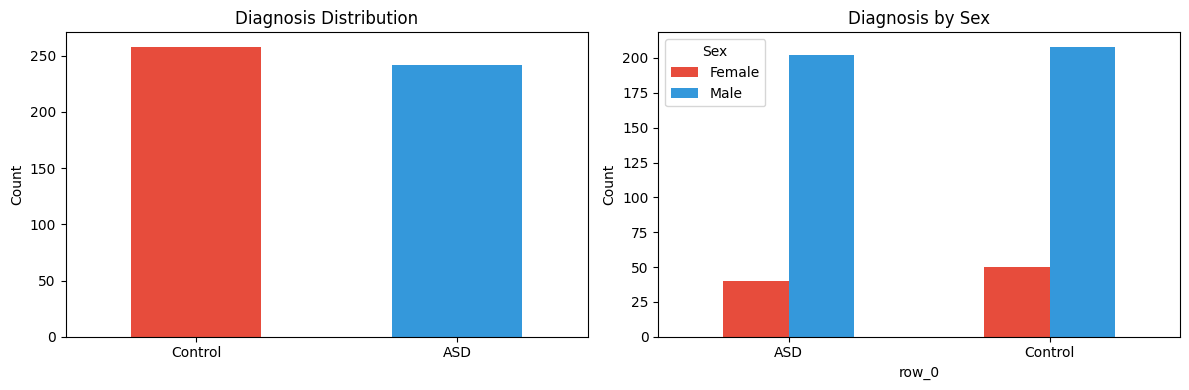

In [5]:
print("Keys:", list(abide_dataset.keys()))

# Cohort size
n_subjects = len(abide_dataset.rois_aal)
print(f"\nNumber of subjects downloaded: {n_subjects}")

# Shape of first subject's time-series
ts_first = abide_dataset.rois_aal[0]
print(f"\nShape of first subject's time-series: {ts_first.shape}")
print(f"  -> {ts_first.shape[0]} time points, {ts_first.shape[1]} brain regions (AAL atlas)")

# Phenotypic info
pheno_df = abide_dataset.phenotypic
print(f"\nPhenotypic columns: {list(pheno_df.columns)}")
print(f"\nDiagnosis distribution (DX_GROUP: 1=ASD, 2=TC):")
print(pheno_df['DX_GROUP'].value_counts())
print(f"\nSex distribution (SEX: 1=Male, 2=Female):")
print(pheno_df['SEX'].value_counts())


# Binary labels: 0=ASD, 1=TC
labels = (pheno_df['DX_GROUP'].values == 2).astype(int)  # 1=control, 0=ASD
sex = pheno_df['SEX'].values  # 1=Male, 2=Female

print(f"Labels shape: {labels.shape}")
print(f"ASD (0): {np.sum(labels == 0)}, Control (1): {np.sum(labels == 1)}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Diagnosis distribution
diag_counts = pd.Series(labels).map({0: 'ASD', 1: 'Control'}).value_counts()
diag_counts.plot(kind='bar', ax=axes[0], color=['#e74c3c', '#3498db'])
axes[0].set_title('Diagnosis Distribution')
axes[0].set_ylabel('Count')
axes[0].tick_params(axis='x', rotation=0)

# Diagnosis by sex
cross = pd.crosstab(
    pd.Series(labels).map({0: 'ASD', 1: 'Control'}),
    pd.Series(sex).map({1: 'Male', 2: 'Female'})
)
cross.plot(kind='bar', ax=axes[1], color=['#e74c3c', '#3498db'])
axes[1].set_title('Diagnosis by Sex')
axes[1].set_ylabel('Count')
axes[1].tick_params(axis='x', rotation=0)
axes[1].legend(title='Sex')

plt.tight_layout()
plt.show()

## Functional connectivity from regional fMRI signals

For each subject, the AAL derivative contains a time series with one signal per brain region. Functional connectivity summarises the statistical relationships between these regional signals and produces a **116 × 116 connectivity matrix** for every subject.

We use **partial correlation** as the primary connectivity measure. Unlike ordinary pairwise correlation, partial correlation estimates the association between two regional signals while accounting for the remaining regions. This gives a subject-level representation of direct statistical dependencies within the observed network.

The matrices below illustrate the connectivity structure of one ASD participant and one control participant.


Connectivity matrices shape: (500, 116, 116)


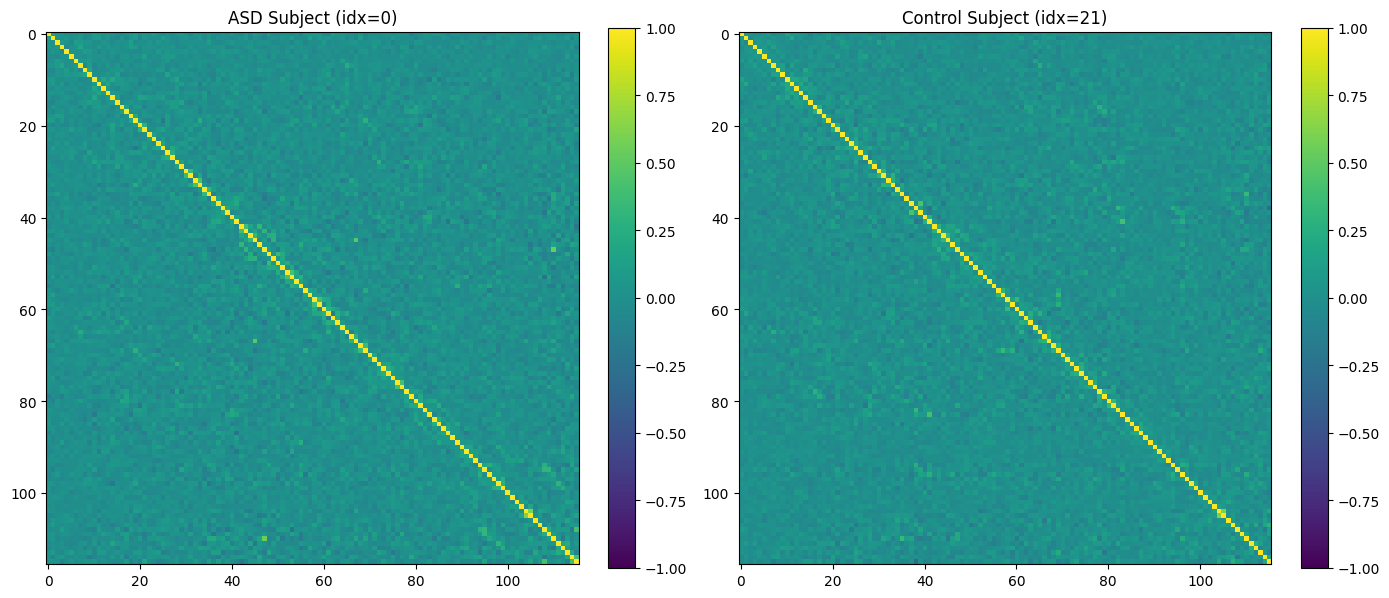

In [7]:
corr_measure = ConnectivityMeasure(kind='partial correlation')
correlation_matrices = corr_measure.fit_transform(abide_dataset['rois_aal'])

print(f"\nConnectivity matrices shape: {correlation_matrices.shape}")

asd_idx = np.where(labels == 0)[0][0]
ctrl_idx = np.where(labels == 1)[0][0]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

im0 = axes[0].imshow(correlation_matrices[asd_idx], cmap='viridis', vmin=-1, vmax=1)
axes[0].set_title(f'ASD Subject (idx={asd_idx})')
plt.colorbar(im0, ax=axes[0], fraction=0.046)

im1 = axes[1].imshow(correlation_matrices[ctrl_idx], cmap='viridis', vmin=-1, vmax=1)
axes[1].set_title(f'Control Subject (idx={ctrl_idx})')
plt.colorbar(im1, ax=axes[1], fraction=0.046)

plt.tight_layout()
plt.show()

### Group-level connectivity patterns

To obtain a first descriptive view of possible group differences, we average the subject-level connectivity matrices separately for ASD and control participants and then compute the control-minus-ASD difference.

The difference map is shown on its own colour scale because its magnitude is much smaller than the connectivity values themselves. It should be interpreted as a descriptive group contrast rather than evidence that an individual connection is diagnostically specific.

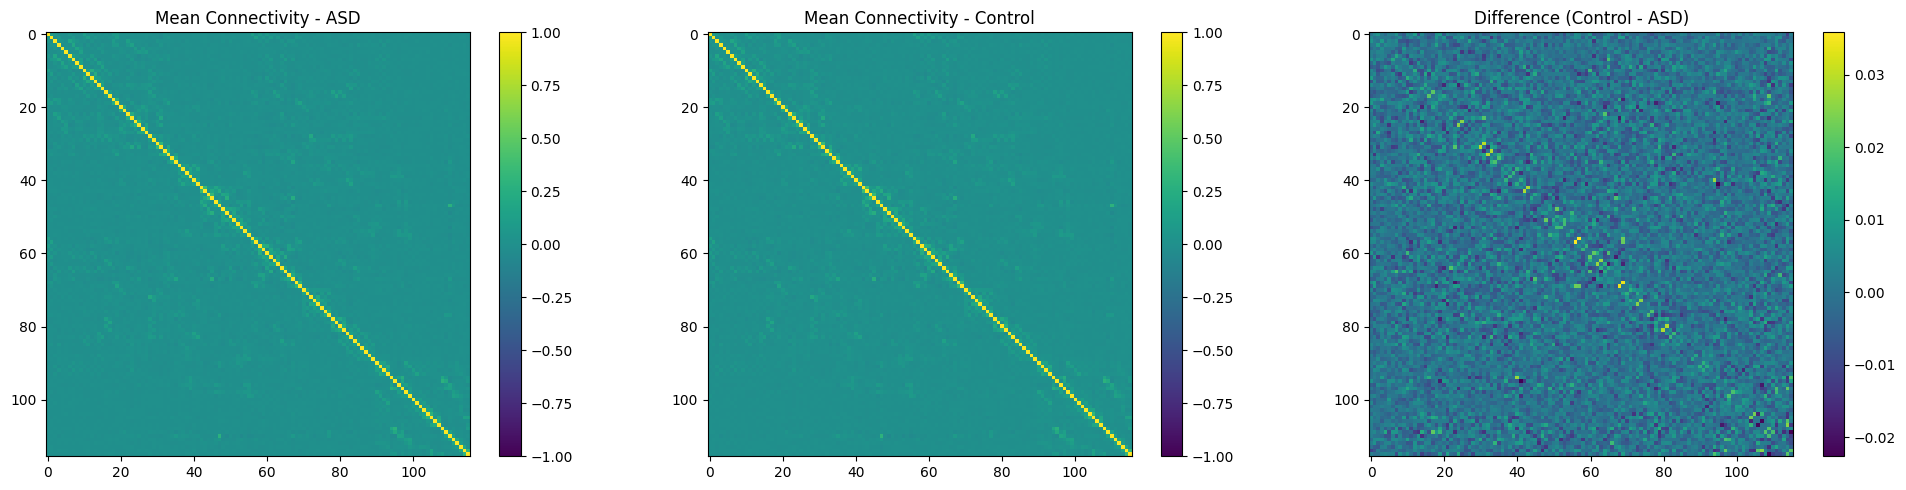

Max absolute difference: 0.0359
Mean absolute difference: 0.0040


In [8]:
tmp_labels_array = (pheno_df['DX_GROUP'].values == 2).astype(int)  # 1=control, 0=ASD
tmp_sex_array = pheno_df['SEX'].values  # 1=Male, 2=Female

mean_asd = correlation_matrices[labels == 0].mean(axis=0)
mean_ctrl = correlation_matrices[labels == 1].mean(axis=0)
diff = mean_ctrl - mean_asd

fig, axes = plt.subplots(1, 3, figsize=(20, 5))

im0 = axes[0].imshow(mean_asd, cmap='viridis', vmin=-1, vmax=1)
axes[0].set_title('Mean Connectivity - ASD')
plt.colorbar(im0, ax=axes[0], fraction=0.046)

im1 = axes[1].imshow(mean_ctrl, cmap='viridis', vmin=-1, vmax=1)
axes[1].set_title('Mean Connectivity - Control')
plt.colorbar(im1, ax=axes[1], fraction=0.046)

im2 = axes[2].imshow(diff, cmap='viridis')#, vmin=-2, vmax=2)
axes[2].set_title('Difference (Control - ASD)')
plt.colorbar(im2, ax=axes[2], fraction=0.046)

plt.tight_layout()
plt.show()

print(f"Max absolute difference: {np.abs(diff).max():.4f}")
print(f"Mean absolute difference: {np.abs(diff).mean():.4f}")

## Vectorising the connectome

A symmetric 116 × 116 connectivity matrix contains redundant entries. For the classical machine-learning baseline, we retain only the **upper triangular values excluding the diagonal** and flatten them into one feature vector per subject.

This produces `X_flat`, where each row represents a subject and each column corresponds to one unique pairwise functional connection. The same underlying connectivity information will later be represented explicitly as a graph for the GAT model.

In [10]:
n_regions = correlation_matrices.shape[1]
triu_idx = np.triu_indices(n_regions, k=1)

# Extract upper triangle for each subject
X_flat = np.array([cm[triu_idx] for cm in correlation_matrices])

print(f"Feature matrix shape: {X_flat.shape}")
print(f"\t{X_flat.shape[0]} subjects, {X_flat.shape[1]} features")
print(f"\t(116 * 115) / 2 = {116 * 115 // 2} unique pairs")

Feature matrix shape: (500, 6670)
	500 subjects, 6670 features
	(116 * 115) / 2 = 6670 unique pairs


## Train, validation, and test partitions

The cohort is divided into **75% training, 15% validation, and 10% test data**. Splitting is stratified jointly by diagnosis and sex so that the relative composition of ASD/control and male/female participants remains similar across partitions.

The test set is held out first. The validation subset is then taken from the remaining subjects, leaving the rest for model fitting. The same subject indices are reused for both the SVM and GAT experiments so that their evaluations are directly comparable.

In [12]:
np.random.seed(42)

# Combined stratification key
strat_key = np.array([f"{l}_{s}" for l, s in zip(labels, sex)])

# First split: 90% train+val, 10% test
sss1 = StratifiedShuffleSplit(n_splits=1, test_size=0.10, random_state=42)
trainval_idx, test_idx = next(sss1.split(X_flat, strat_key))

# Second split: from trainval, take ~16.7% as validation (≈15% of total)
sss2 = StratifiedShuffleSplit(n_splits=1, test_size=0.167, random_state=42)
train_idx_rel, val_idx_rel = next(sss2.split(X_flat[trainval_idx], strat_key[trainval_idx]))

# Map relative indices back to original
train_idx = trainval_idx[train_idx_rel]
val_idx = trainval_idx[val_idx_rel]

print(f"Total subjects: {len(labels)}")
print(f"Train: {len(train_idx)} ({len(train_idx)/len(labels)*100:.1f}%)")
print(f"Val:   {len(val_idx)} ({len(val_idx)/len(labels)*100:.1f}%)")
print(f"Test:  {len(test_idx)} ({len(test_idx)/len(labels)*100:.1f}%)")

# Check distributions
for name, idx in [('Train', train_idx), ('Val', val_idx), ('Test', test_idx)]:
    n_asd = np.sum(labels[idx] == 0)
    n_ctrl = np.sum(labels[idx] == 1)
    n_male = np.sum(sex[idx] == 1)
    n_female = np.sum(sex[idx] == 2)
    print(f"\n{name}: ASD={n_asd}, Ctrl={n_ctrl} | Male={n_male}, Female={n_female}")

Total subjects: 500
Train: 374 (74.8%)
Val:   76 (15.2%)
Test:  50 (10.0%)

Train: ASD=181, Ctrl=193 | Male=307, Female=67

Val: ASD=37, Ctrl=39 | Male=62, Female=14

Test: ASD=24, Ctrl=26 | Male=41, Female=9


## SVM baseline on functional connections

The first classifier uses the vectorised upper triangle of each partial-correlation matrix. A radial-basis-function SVM provides a conventional neuroimaging baseline against which the graph model can later be compared.

The pipeline standardises the connectivity features before fitting the SVM. Performance is examined on the validation set using accuracy, balanced accuracy, F1 score, and ROC-AUC, followed by a final evaluation on the held-out test set. A confusion matrix makes the class-specific behaviour visible.

SVM Validation Performance
Accuracy:          0.5263
Balanced Accuracy: 0.5184
F1 Score:          0.6400
AUC-ROC:           0.5925

Classification Report:
              precision    recall  f1-score   support

         ASD       0.53      0.22      0.31        37
     Control       0.52      0.82      0.64        39

    accuracy                           0.53        76
   macro avg       0.53      0.52      0.47        76
weighted avg       0.53      0.53      0.48        76



SVM Test Performance
Accuracy:          0.6400
Balanced Accuracy: 0.6266
F1 Score:          0.7353
AUC-ROC:           0.7420


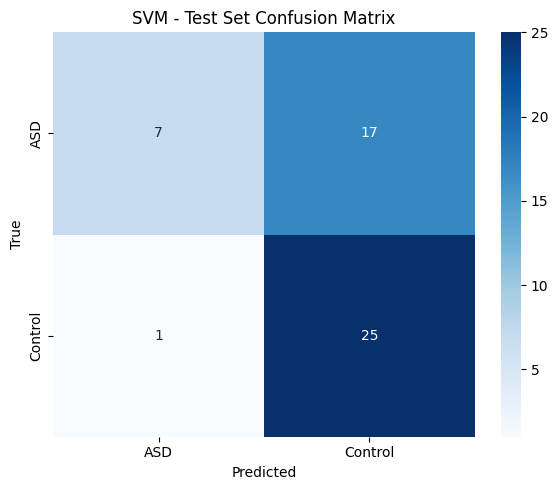

In [14]:
X_train, y_train = X_flat[train_idx], labels[train_idx]
X_val, y_val = X_flat[val_idx], labels[val_idx]
X_test, y_test = X_flat[test_idx], labels[test_idx]


svm_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(kernel='rbf', C=1.0, probability=True, random_state=42))
])

# Fit the SVM
svm_pipeline.fit(X_train, y_train)

# Validation performance
y_val_pred = svm_pipeline.predict(X_val)
y_val_proba = svm_pipeline.predict_proba(X_val)[:, 1]

print("SVM Validation Performance")
print(f"Accuracy:          {accuracy_score(y_val, y_val_pred):.4f}")
print(f"Balanced Accuracy: {balanced_accuracy_score(y_val, y_val_pred):.4f}")
print(f"F1 Score:          {f1_score(y_val, y_val_pred):.4f}")
print(f"AUC-ROC:           {roc_auc_score(y_val, y_val_proba):.4f}")
print(f"\nClassification Report:\n{classification_report(y_val, y_val_pred, target_names=['ASD', 'Control'])}")

# Held-out test performance
y_test_pred_svm = svm_pipeline.predict(X_test)
y_test_proba_svm = svm_pipeline.predict_proba(X_test)[:, 1]

svm_test_acc = accuracy_score(y_test, y_test_pred_svm)
svm_test_bacc = balanced_accuracy_score(y_test, y_test_pred_svm)
svm_test_f1 = f1_score(y_test, y_test_pred_svm)
svm_test_auc = roc_auc_score(y_test, y_test_proba_svm)

print("\n")
print("SVM Test Performance")
print(f"Accuracy:          {svm_test_acc:.4f}")
print(f"Balanced Accuracy: {svm_test_bacc:.4f}")
print(f"F1 Score:          {svm_test_f1:.4f}")
print(f"AUC-ROC:           {svm_test_auc:.4f}")

# Test-set confusion matrix
cm = confusion_matrix(y_test, y_test_pred_svm)
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['ASD', 'Control'],
            yticklabels=['ASD', 'Control'], ax=ax)
ax.set_xlabel('Predicted')
ax.set_ylabel('True')
ax.set_title('SVM - Test Set Confusion Matrix')
plt.tight_layout()
plt.show()

## Representing each connectome as a graph

The second part of the analysis keeps the network structure explicit instead of flattening the connectivity matrix. Each subject is represented as a brain graph in which:

- **nodes** are the 116 AAL regions;
- **edges** are functional connections retained from the subject's connectivity matrix;
- **edge attributes** are the corresponding partial-correlation values;
- **node features** combine anatomical position with subject-specific connectivity summaries;
- **graph labels** indicate ASD or control status.

AAL region centres are expressed in MNI space as \((x, y, z)\) coordinates. These coordinates provide a common anatomical reference across subjects and are min-max normalised before being passed to the graph model.

Spatial coordinates alone are identical across subjects, so they cannot encode individual functional differences. The graph construction below therefore augments them with four subject-specific node descriptors: absolute node strength, thresholded degree, mean connectivity, and connectivity standard deviation. Each node is consequently described by seven features.

In [15]:
atlas = datasets.fetch_atlas_aal(version='SPM12')
coordinates = find_parcellation_cut_coords(labels_img=atlas['maps'])

print(f"Atlas regions: {len(atlas['labels'])} (there is an extra Background region)")
print(f"Coordinates shape: {coordinates.shape}")
print(f"First 5 regions: {atlas['labels'][:5]}")
print(f"First 5 coordinates:\n{coordinates[:5]}")

[fetch_atlas_aal] Dataset created in /root/nilearn_data/aal_SPM12

[fetch_atlas_aal] Downloading data from https://www.gin.cnrs.fr/AAL_files/aal_for_SPM12.tar.gz ...

[fetch_atlas_aal] Error while fetching file aal_for_SPM12.tar.gz; dataset fetching aborted.

[fetch_atlas_aal] Downloading data from https://osf.io/s94qg/download ...

[fetch_atlas_aal] Downloaded 163840 of 351343 bytes (46.6%%, 00 HR 00 MIN 01 SEC remaining)

[fetch_atlas_aal]  ...done. (6 seconds, 0 min)

[fetch_atlas_aal] Extracting data from /root/nilearn_data/aal_SPM12/a41098130c898ca539136bc99f7c82af/download...

[fetch_atlas_aal] .. done.

Atlas regions: 117 (there is an extra Background region)
Coordinates shape: (116, 3)
First 5 regions: ['Background', 'Precentral_L', 'Precentral_R', 'Frontal_Sup_L', 'Frontal_Sup_R']
First 5 coordinates:
[[-38.92822695  -6.96        49.64652482]
 [ 41.10085773  -9.54983733  50.80981958]
 [-18.79777159  33.4178273   40.99442897]
 [ 21.60483473  29.9097188   42.51307351]
 [-16.82450675  45.91900312 -14.71858775]]


In [16]:
# Min-Max normalisation of coordinates
coord_min = coordinates.min(axis=0)
coord_max = coordinates.max(axis=0)
coords_normalised = (coordinates - coord_min) / (coord_max - coord_min)

print(f"Normalised coordinates shape: {coords_normalised.shape}")
print(f"Min per axis: {coords_normalised.min(axis=0)}")
print(f"Max per axis: {coords_normalised.max(axis=0)}")
print(f"\nFirst 5 normalised coordinates:\n{coords_normalised[:5]}")

# Convert to tensor (will be reused for all subjects)
node_features = torch.tensor(coords_normalised, dtype=torch.float32)
print(f"\nNode features tensor shape: {node_features.shape}")

Normalised coordinates shape: (116, 3)
Min per axis: [0. 0. 0.]
Max per axis: [1. 1. 1.]

First 5 normalised coordinates:
[[0.15106524 0.5704857  0.8383031 ]
 [0.85320388 0.55170051 0.84801187]
 [0.32768066 0.86336318 0.76609337]
 [0.68215468 0.83791738 0.77876786]
 [0.34499319 0.9540395  0.3011168 ]]

Node features tensor shape: torch.Size([116, 3])


### From connectivity matrices to PyTorch Geometric graphs

A subject's dense connectivity matrix is converted into a sparse graph by retaining connections whose absolute partial correlation exceeds the chosen threshold (`0.3` in the implementation below).

For every subject, the resulting `Data` object contains the seven-dimensional node features, the sparse edge index, the signed connectivity value attached to each retained edge, and the diagnostic label. Summary statistics are printed to show how many edges remain after thresholding and how graph density varies across subjects.

In [18]:
def create_graph(corr_matrix, label, base_node_feats, threshold=0.3):
    """
    Convert a correlation matrix into a PyG Data object
    with enriched, subject-specific node features.
    """
    n = corr_matrix.shape[0]

    # Subject-specific node features

    # Node strength: sum of absolute correlations per region
    abs_corr = np.abs(corr_matrix.copy())
    np.fill_diagonal(abs_corr, 0)
    node_strength = abs_corr.sum(axis=1)  # (116,)

    # Node degree: number of connections above threshold
    node_degree = (abs_corr > threshold).sum(axis=1).astype(float)  # (116,)

    # Mean connectivity per region
    np.fill_diagonal(corr_matrix, 0)
    node_mean_conn = corr_matrix.mean(axis=1)  # (116,)

    # Std of connectivity per region
    node_std_conn = corr_matrix.std(axis=1)  # (116,)

    # Stack into per-node feature vector
    subject_feats = np.column_stack([
        node_strength,
        node_degree,
        node_mean_conn,
        node_std_conn,
    ])  # (116, 4)

    # Normalise subject-specific features (per-subject z-score)
    feat_mean = subject_feats.mean(axis=0, keepdims=True)
    feat_std = subject_feats.std(axis=0, keepdims=True) + 1e-8
    subject_feats = (subject_feats - feat_mean) / feat_std

    # Concatenate with spatial coordinates: (116, 3) + (116, 4) = (116, 7)
    all_feats = np.concatenate([
        base_node_feats.numpy(),  # coordinates
        subject_feats
    ], axis=1)

    node_features = torch.tensor(all_feats, dtype=torch.float32)

    # Sparse edges and edge weights
    abs_corr2 = np.abs(corr_matrix.copy())
    np.fill_diagonal(abs_corr2, 0)
    row, col = np.where(abs_corr2 > threshold)

    edge_index = torch.tensor(np.array([row, col]), dtype=torch.long)
    edge_weights = torch.tensor(
        corr_matrix[row, col], dtype=torch.float32
    ).unsqueeze(1)

    data = Data(
        x=node_features,
        edge_index=edge_index,
        edge_attr=edge_weights,
        y=torch.tensor([label], dtype=torch.long)
    )
    return data

# Create graph dataset
THRESHOLD = 0.05
graph_list = []
for i in range(len(correlation_matrices)):
    g = create_graph(correlation_matrices[i], labels[i], node_features, threshold=THRESHOLD)
    graph_list.append(g)

print(f"Created {len(graph_list)} graphs")
print(f"\nExample graph: {graph_list[0]}")

# Summary statistics
n_edges = [g.edge_index.shape[1] for g in graph_list]
print(f"\nEdge statistics:")
print(f"  Mean edges:   {np.mean(n_edges):.0f}")
print(f"  Min edges:    {np.min(n_edges)}")
print(f"  Max edges:    {np.max(n_edges)}")
print(f"  Mean density: {np.mean(n_edges) / (116 * 115):.3f}")

Created 500 graphs

Example graph: Data(x=[116, 7], edge_index=[2, 5166], edge_attr=[5166, 1], y=[1])

Edge statistics:
  Mean edges:   4533
  Min edges:    342
  Max edges:    6324
  Mean density: 0.340


### Graph data loaders

The graph dataset uses exactly the same training, validation, and test subject indices as the SVM analysis. This avoids changing the evaluation population when comparing the two modelling approaches.

PyTorch Geometric data loaders then batch multiple subject graphs together during training and evaluation.

In [20]:
train_graphs = [graph_list[i] for i in train_idx]
val_graphs = [graph_list[i] for i in val_idx]
test_graphs = [graph_list[i] for i in test_idx]

BATCH_SIZE = 32

train_loader = DataLoader(train_graphs, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_graphs, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_graphs, batch_size=BATCH_SIZE, shuffle=False)

print(f"Train batches: {len(train_loader)}")
print(f"Val batches:   {len(val_loader)}")
print(f"Test batches:  {len(test_loader)}")

# Inspect one training batch
batch = next(iter(train_loader))
print(f"\nExample batch: {batch}")
print(f"Batch x shape: {batch.x.shape}")
print(f"Batch edge_index shape: {batch.edge_index.shape}")
print(f"Batch y: {batch.y}")

Train batches: 12
Val batches:   3
Test batches:  2

Example batch: DataBatch(x=[3712, 7], edge_index=[2, 139354], edge_attr=[139354, 1], y=[32], batch=[3712], ptr=[33])
Batch x shape: torch.Size([3712, 7])
Batch edge_index shape: torch.Size([2, 139354])
Batch y: tensor([1, 1, 0, 0, 1, 1, 0, 1, 0, 1, 0, 0, 0, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0,
        1, 1, 1, 0, 0, 1, 1, 1])


/tmp/ipykernel_2829/1499428431.py:8: UserWarning: 'data.DataLoader' is deprecated, use 'loader.DataLoader' instead
  train_loader = DataLoader(train_graphs, batch_size=BATCH_SIZE, shuffle=True)
/tmp/ipykernel_2829/1499428431.py:9: UserWarning: 'data.DataLoader' is deprecated, use 'loader.DataLoader' instead
  val_loader = DataLoader(val_graphs, batch_size=BATCH_SIZE, shuffle=False)
/tmp/ipykernel_2829/1499428431.py:10: UserWarning: 'data.DataLoader' is deprecated, use 'loader.DataLoader' instead
  test_loader = DataLoader(test_graphs, batch_size=BATCH_SIZE, shuffle=False)


### Graph Attention Network

The graph classifier is a two-layer **Graph Attention Network (GAT)**. The first `GATConv` layer uses multi-head attention to learn how neighbouring regions contribute to each node representation. A second attention layer produces the final node embeddings.

`global_mean_pool` aggregates the node embeddings into one representation per subject, and a linear layer maps that graph-level representation to the two diagnostic classes. Edge weights are supplied to the attention layers as one-dimensional edge attributes.

The implemented model uses seven input features per node, four attention heads in the first layer, eight hidden channels, and dropout during training.

In [22]:
class BrainGAT(nn.Module):
    def __init__(self, in_channels, hidden_channels, out_channels, heads=4, dropout=0.1):
        super(BrainGAT, self).__init__()
        self.dropout = dropout
        self.gat1 = GATConv(in_channels, hidden_channels, heads=heads, dropout=dropout, edge_dim=1)
        self.gat2 = GATConv(hidden_channels * heads, hidden_channels, heads=1,
                            concat=False, dropout=dropout, edge_dim=1)
        self.lin = nn.Linear(hidden_channels, out_channels)

    def forward(self, x, edge_index, batch, edge_attr=None):
        # First GAT layer
        # Set return_attention_weights=True to get the learned attention scores
        x, (edge_idx1, att_weights1) = self.gat1(x, edge_index, edge_attr=edge_attr, return_attention_weights=True)
        x = F.elu(x)
        x = F.dropout(x, p=self.dropout, training=self.training)

        # Second GAT layer
        x, (edge_idx2, att_weights2) = self.gat2(x, edge_index, edge_attr=edge_attr, return_attention_weights=True)
        x = F.elu(x)

        # Readout layer
        x = global_mean_pool(x, batch)

        # Final classifier
        x = F.dropout(x, p=self.dropout, training=self.training)
        x = self.lin(x)

        return x, (edge_idx1, att_weights1), (edge_idx2, att_weights2)

# Initialize the model
model = BrainGAT(
    in_channels=7, # x, y, z coordinates
    hidden_channels=8,
    out_channels=2, # ASD vs Control
    heads=4,
    dropout=0.1
).to(device)

print(model)
total_params = sum(p.numel() for p in model.parameters())
print(f"\nTotal parameters: {total_params:,}")

BrainGAT(
  (gat1): GATConv(7, 8, heads=4)
  (gat2): GATConv(32, 8, heads=1)
  (lin): Linear(in_features=8, out_features=2, bias=True)
)

Total parameters: 698


## Training the GAT

The GAT is optimised with Adam and cross-entropy loss for 100 epochs. Training loss and accuracy are tracked together with validation loss and accuracy after every epoch.

Model selection is based on the **lowest validation loss**: whenever validation loss improves, a copy of the corresponding model parameters is retained. The learning curves below make it possible to inspect optimisation behaviour and the separation between training and validation performance.

In [24]:
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-3)
criterion = nn.CrossEntropyLoss()

def train_one_epoch(model, loader, optimizer, criterion, device):
    model.train()
    total_loss = 0
    correct = 0
    total = 0

    for batch in loader:
        batch = batch.to(device)
        optimizer.zero_grad()

        out, _, _ = model(batch.x, batch.edge_index, batch.batch, edge_attr=batch.edge_attr)
        loss = criterion(out, batch.y)

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * batch.num_graphs
        pred = out.argmax(dim=1)
        correct += (pred == batch.y).sum().item()
        total += batch.num_graphs

    return total_loss / total, correct / total


@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss = 0
    correct = 0
    total = 0
    all_preds = []
    all_labels = []
    all_probs = []

    for batch in loader:
        batch = batch.to(device)
        out, _, _ = model(batch.x, batch.edge_index, batch.batch, edge_attr=batch.edge_attr)
        loss = criterion(out, batch.y)

        total_loss += loss.item() * batch.num_graphs
        pred = out.argmax(dim=1)
        probs = F.softmax(out, dim=1)

        correct += (pred == batch.y).sum().item()
        total += batch.num_graphs
        all_preds.extend(pred.cpu().numpy())
        all_labels.extend(batch.y.cpu().numpy())
        all_probs.extend(probs[:, 1].cpu().numpy())

    return (
        total_loss / total,
        correct / total,
        np.array(all_preds),
        np.array(all_labels),
        np.array(all_probs)
    )

In [25]:
# Fit the SVMing loop
NUM_EPOCHS = 100

history = {
    'train_loss': [], 'train_acc': [],
    'val_loss': [], 'val_acc': []
}

best_val_loss = 99999
best_model_state = None

for epoch in range(1, NUM_EPOCHS + 1):
    train_loss, train_acc = train_one_epoch(model, train_loader, optimizer, criterion, device)
    val_loss, val_acc, _, _, _ = evaluate(model, val_loader, criterion, device)

    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)

    # Keep the parameters with the lowest validation loss
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_model_state = {k: v.clone() for k, v in model.state_dict().items()}

    if epoch % 10 == 0:
        print(f"Epoch {epoch:3d} | Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f} | "
              f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}")

print(f"\nBest validation loss: {best_val_loss:.4f}")

Epoch  10 | Train Loss: 0.6932 | Train Acc: 0.5160 | Val Loss: 0.6950 | Val Acc: 0.5132
Epoch  20 | Train Loss: 0.6916 | Train Acc: 0.5321 | Val Loss: 0.6956 | Val Acc: 0.4868
Epoch  30 | Train Loss: 0.6929 | Train Acc: 0.5214 | Val Loss: 0.6964 | Val Acc: 0.5000
Epoch  40 | Train Loss: 0.6912 | Train Acc: 0.5401 | Val Loss: 0.6972 | Val Acc: 0.4737
Epoch  50 | Train Loss: 0.6919 | Train Acc: 0.5107 | Val Loss: 0.6981 | Val Acc: 0.4868
Epoch  60 | Train Loss: 0.6892 | Train Acc: 0.5401 | Val Loss: 0.6988 | Val Acc: 0.4868
Epoch  70 | Train Loss: 0.6906 | Train Acc: 0.5455 | Val Loss: 0.6995 | Val Acc: 0.4737
Epoch  80 | Train Loss: 0.6906 | Train Acc: 0.5374 | Val Loss: 0.7005 | Val Acc: 0.4868
Epoch  90 | Train Loss: 0.6904 | Train Acc: 0.5321 | Val Loss: 0.7017 | Val Acc: 0.4737
Epoch 100 | Train Loss: 0.6900 | Train Acc: 0.5214 | Val Loss: 0.7024 | Val Acc: 0.4737

Best validation loss: 0.6940


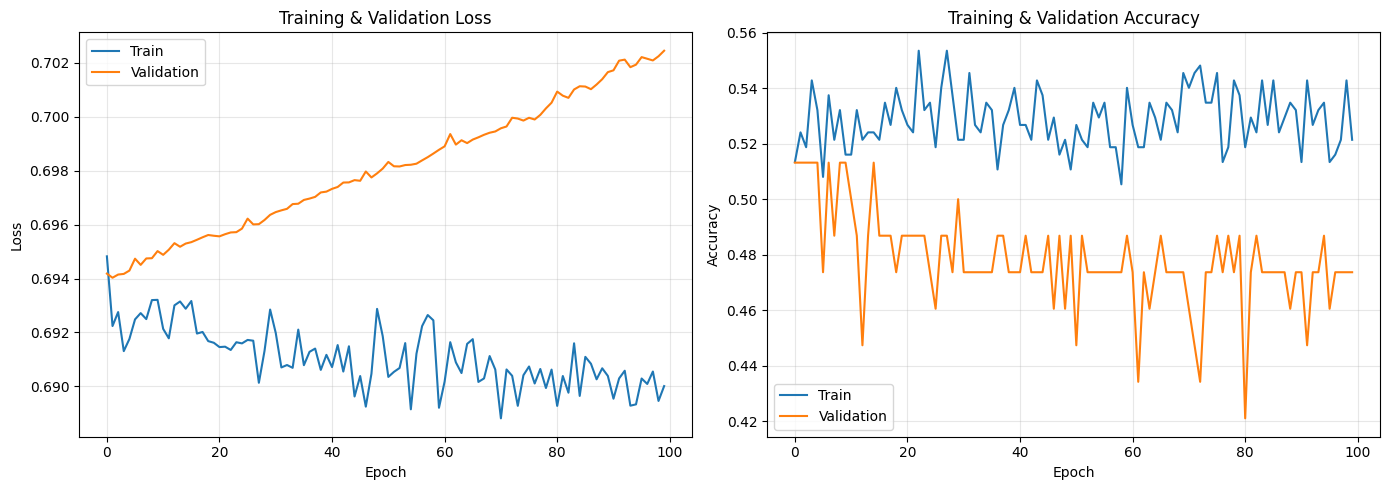

In [26]:
# Training and validation trajectories
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history['train_loss'], label='Train')
axes[0].plot(history['val_loss'], label='Validation')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].set_title('Training & Validation Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(history['train_acc'], label='Train')
axes[1].plot(history['val_acc'], label='Validation')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].set_title('Training & Validation Accuracy')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Held-out GAT evaluation

After training, the parameters associated with the lowest validation loss are restored and evaluated once on the held-out test set.

The final evaluation reports accuracy, balanced accuracy, F1 score, and ROC-AUC, followed by the classification report and confusion matrix. Because the SVM and GAT use the same test subjects, their results can be compared on a common split.

GAT Test Performance
Accuracy:          0.5200
Balanced Accuracy: 0.5000
F1 Score:          0.6842
AUC-ROC:           0.4696

Classification Report:
              precision    recall  f1-score   support

         ASD       0.00      0.00      0.00        24
     Control       0.52      1.00      0.68        26

    accuracy                           0.52        50
   macro avg       0.26      0.50      0.34        50
weighted avg       0.27      0.52      0.36        50



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


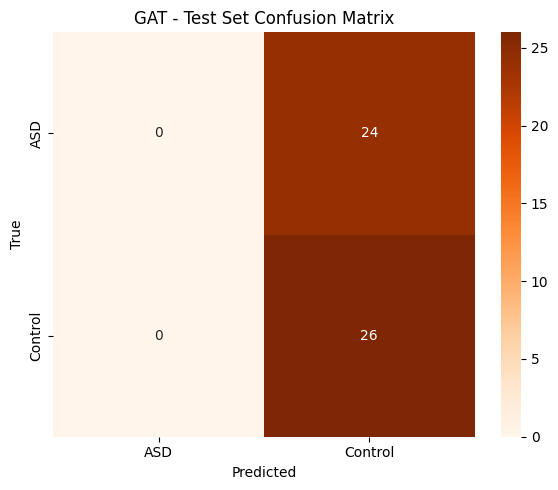

In [28]:
# Restore the best validation checkpoint
model.load_state_dict(best_model_state)

# Held-out test evaluation
test_loss, test_acc, y_test_pred_gat, y_test_true_gat, y_test_proba_gat = evaluate(
    model, test_loader, criterion, device
)

gat_test_acc = accuracy_score(y_test_true_gat, y_test_pred_gat)
gat_test_bacc = balanced_accuracy_score(y_test_true_gat, y_test_pred_gat)
gat_test_f1 = f1_score(y_test_true_gat, y_test_pred_gat)
gat_test_auc = roc_auc_score(y_test_true_gat, y_test_proba_gat)

print("GAT Test Performance")
print(f"Accuracy:          {gat_test_acc:.4f}")
print(f"Balanced Accuracy: {gat_test_bacc:.4f}")
print(f"F1 Score:          {gat_test_f1:.4f}")
print(f"AUC-ROC:           {gat_test_auc:.4f}")
print(f"\nClassification Report:")
print(classification_report(y_test_true_gat, y_test_pred_gat, target_names=['ASD', 'Control']))

# Test-set confusion matrix
cm_gat = confusion_matrix(y_test_true_gat, y_test_pred_gat)
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm_gat, annot=True, fmt='d', cmap='Oranges',
            xticklabels=['ASD', 'Control'],
            yticklabels=['ASD', 'Control'], ax=ax)
ax.set_xlabel('Predicted')
ax.set_ylabel('True')
ax.set_title('GAT - Test Set Confusion Matrix')
plt.tight_layout()
plt.show()